# 04 - Baseline: Cleaning & Training Lama (tanpa modifikasi)

Notebook ini menjalankan ulang **metode asli proyek** sebagai pembanding (baseline) untuk notebook 01-03:

- **Cleaning lama** = fungsi `clean_text` dari `Deployment/app/worker.py` (dipakai sistem saat memprediksi komentar hasil scraping)
- **Training lama** = alur `Jupyterlab/Gambling_Trainer_kagle.ipynb` (melatih model dari kolom `komentar_clean` bawaan dataset)

Kodenya disalin apa adanya. Penyesuaian hanya yang diperlukan agar bisa jalan di Python/library terbaru:
| Penyesuaian | Alasan |
|---|---|
| `nltk.download("punkt_tab")` | NLTK >= 3.9 memindahkan data tokenizer ke `punkt_tab` |
| daftar emoji YouTube ditanam di notebook | `youtubeemoji.csv` tidak tersedia di Colab; isinya sama (kolom `Emoji label`) |
| daftar bendera ditulis `chr(0x1F1E6)` ... `chr(0x1F1FF)` | isinya sama dengan 26 karakter huruf bendera di `worker.py` |
| path dataset memakai `kagglehub` | path `/kaggle/input/...` hanya ada di Kaggle |
| peringatan `FutureWarning` disembunyikan | `SVC(probability=True)` deprecated di scikit-learn 1.9, tetapi masih berjalan |

Isi:
1. Setup & load data
2. Cleaning lama (`worker.py`) dan perilakunya pada komentar yang disamarkan
3. **Bagian A** - replikasi persis training lama (termasuk kebocoran data)
4. **Bagian B** - ketidakcocokan cleaning training vs prediksi
5. **Bagian C** - cleaning lama dievaluasi dengan protokol yang adil + uji ketahanan
6. Ringkasan perbandingan dengan cleaning v2 (notebook 02)

## 1. Setup & load data

In [1]:
%pip install -q kagglehub emoji nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import os
import re
import warnings

import emoji
import joblib
import kagglehub
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.utils import resample

warnings.filterwarnings("ignore", category=FutureWarning)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
pd.set_option("display.max_colwidth", 120)

import matplotlib.pyplot as plt
import seaborn as sns

# Palet konsisten di semua notebook: biru = komentar normal, oranye = promosi judi
WARNA_LABEL = {0: "#2a78d6", 1: "#eb6834"}
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

/home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
path = kagglehub.dataset_download("yaemico/judionline")
file_path = glob.glob(os.path.join(path, "*.csv"))[0]
df_asli = pd.read_csv(file_path)
print(df_asli.shape)
df_asli.head()

(10230, 9)


,video_id,title,channel_name,tanggal,author,komentar,label,komentar_clean,predicted_label
0,f8UEkmYXlzA,SKAKMAT AHOK,Pandji Pragiwaksono,1.745.412.234.123.970,TerranceNoelle-o9i,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,makin yakin abis baca review lain tentang 𝐒𝐆𝐈𝟖𝟖 .,0
1,XI8K0-_kbHc,GAK NYANGKA BISA BEGINI! PENGENDARA DIJALAN SAMPAI BINGUNG LIHAT HUMMER EV | GLAMOUR AUTO BOUTIQUE,Jejelogy,1.739.601.493.342.000,deraatvexplorerriders.2113,Paling suka model H2 😍🔥,0,suka model h2,0
2,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.772.479.808.090,risqokurniadi7208,Mobilnya udah hancur 🥺,0,mobilnya udah hancur,0
3,QpXcKzQInXg,Review Mobil Drift Seharga Super Car | BRZ V8 Obell,Garasi Drift,1.738.825.556.100.780,LorrianeDotson,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin sultan,1
4,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.858.865.953.920,Elpoco7365,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,0


## 2. Cleaning lama (`worker.py`)

Disalin dari `worker.py`. Urutannya: hapus emoji -> hapus huruf bendera -> hapus emoji YouTube -> huruf kecil -> hapus URL ->
hapus mention/hashtag -> rapikan spasi -> tokenisasi NLTK -> hapus stopword.

Perhatikan yang **tidak** dilakukan: tidak ada normalisasi Unicode, tidak ada penanganan homoglif/huruf dispasi, dan tanda
baca tidak dihapus (hanya dipisah oleh tokenizer).

In [4]:
YT_EMOJI_LABELS = [
    ':hand-pink-waving:',
    ':face-blue-smiling:',
    ':face-red-droopy-eyes:',
    ':face-purple-crying:',
    ':text-green-game-over:',
    ':person-turqouise-waving:',
    ':face-green-smiling:',
    ':face-orange-frowning:',
    ':eyes-purple-crying:',
    ':face-fuchsia-wide-eyes:',
    ':cat-orange-whistling:',
    ':face-blue-wide-eyes:',
    ':face-orange-raised-eyebrow:',
    ':face-fuchsia-tongue-out:',
    ':face-orange-biting-nails:',
    ':face-red-heart-shape:',
    ':face-fuchsia-poop-shape:',
    ':face-purple-wide-eyes:',
    ':glasses-purple-yellow-diamond:',
    ':face-pink-tears:',
    ':body-blue-raised-arms:',
    ':hand-orange-covering-eyes:',
    ':trophy-yellow-smiling:',
    ':eyes-pink-heart-shape:',
    ':face-turquoise-covering-eyes:',
    ':hand-green-crystal-ball:',
    ':face-turquoise-drinking-coffee:',
    ':body-green-covering-eyes:',
    ':goat-turquoise-white-horns:',
    ':hand-purple-blue-peace:',
    ':face-blue-question-mark:',
    ':face-blue-covering-eyes:',
    ':face-purple-smiling-fangs:',
    ':face-purple-sweating:',
    ':face-purple-smiling-tears:',
    ':face-blue-star-eyes:',
    ':face-blue-heart-eyes:',
    ':face-blue-three-eyes:',
    ':face-blue-droopy-eyes:',
    ':planet-orange-purple-ring:',
    ':face-turquoise-speaker-shape:',
    ':octopus-red-waving:',
    ':pillow-turquoise-hot-chocolate:',
    ':hourglass-purple-sand-orange:',
    ':fish-orange-wide-eyes:',
    ':popcorn-yellow-striped-smile:',
    ':penguin-blue-waving-tear:',
    ':clock-turquoise-looking-up:',
    ':face-red-smiling-live:',
    ':hands-yellow-heart-red:',
    ':volcano-green-lava-orange:',
    ':person-turquoise-waving-speech:',
    ':face-orange-tv-shape:',
    ':face-blue-spam-shape:',
    ':face-fuchsia-flower-shape:',
    ':person-blue-holding-pencil:',
    ':body-turquoise-yoga-pose:',
    ':location-yellow-teal-bars:',
    ':person-turquoise-writing-headphones:',
    ':person-turquoise-wizard-wand:',
    ':person-blue-eating-spaghetti:',
    ':face-turquoise-music-note:',
    ':person-pink-swaying-hair:',
    ':person-blue-speaking-microphone:',
    ':rocket-red-countdown-liftoff:',
    ':face-purple-rain-drops:',
    ':face-pink-drinking-tea:',
    ':person-purple-stage-event:',
    ':face-purple-open-box:',
    ':person-yellow-podium-blue:',
    ':baseball-white-cap-out:',
    ':whistle-red-blow:',
    ':person-turquoise-crowd-surf:',
    ':finger-red-number-one:',
    ':text-yellow-goal:',
    ':medal-yellow-first-red:',
    ':person-blue-wheelchair-race:',
    ':card-red-penalty:',
    ':stopwatch-blue-hand-timer:',
    ':yt:',
    ':oops:',
    ':buffering:',
    ':stayhome:',
    ':dothefive:',
    ':elbowbump:',
    ':goodvibes:',
    ':thanksdoc:',
    ':videocall:',
    ':virtualhug:',
    ':yougotthis:',
    ':sanitizer:',
    ':takeout:',
    ':hydrate:',
    ':chillwcat:',
    ':chillwdog:',
    ':elbowcough:',
    ':learning:',
    ':washhands:',
    ':socialdist:',
    ':shelterin:',
]

In [5]:
# --- Disalin dari worker.py ---
yt_emoji_pattern = re.compile('|'.join(re.escape(e) for e in YT_EMOJI_LABELS))

def remove_flags(text):
    flags = [chr(c) for c in range(0x1F1E6, 0x1F200)]   # = 26 huruf bendera A-Z di worker.py
    return ''.join(c for c in text if c not in flags)

def clean_text(text):
    if pd.isna(text): return ''

    text = str(text)
    text = emoji.replace_emoji(text, replace='')  # Hapus semua emoji
    text = remove_flags(text)
    text = yt_emoji_pattern.sub('', text)  # Hapus emoji khusus YouTube
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)  # Hapus URL
    text = re.sub(r'@\w+|\#\w+', '', text)  # Hapus mention dan hashtag
    text = re.sub(r'\n', ' ', text)  # Hapus newline
    text = re.sub(r'\s+', ' ', text).strip()  # Normalisasi spasi

    # Tokenisasi dengan stopwords Bahasa Indonesia
    tokens = word_tokenize(text)
    stop_words = set(stopwords.words('indonesian'))
    tokens = [w for w in tokens if w not in stop_words]

    return ' '.join(tokens)

def preprocess_comments(comments):
    # Dipakai worker sebelum prediksi (tidak dipakai saat training lama)
    if not comments:
        return []
    df = pd.DataFrame(comments)
    df['cleaned_text'] = df['text'].apply(clean_text)
    df['text_length'] = df['cleaned_text'].str.len()
    df = df[(df['text_length'] >= 10) & (df['text_length'] <= 70)]
    df.drop_duplicates(subset=['cleaned_text'], keep='first', inplace=True)
    return df.to_dict('records')

### Perilaku pada komentar yang disamarkan

Komentar contoh yang sama dengan notebook 01. Huruf "fancy" **tidak berubah** (tetap token berbeda dari `alexis17`),
emoji **hilang tanpa jejak**, dan huruf dispasi tetap terpisah.

In [6]:
BOLD = {**{chr(ord("A") + i): chr(0x1D400 + i) for i in range(26)},
        **{chr(ord("a") + i): chr(0x1D41A + i) for i in range(26)},
        **{chr(ord("0") + i): chr(0x1D7CE + i) for i in range(10)}}
CYRILLIC = {"a": "\u0430", "e": "\u0435", "o": "\u043e", "p": "\u0440", "c": "\u0441", "x": "\u0445"}
CAMPURAN = {"a": "\u03b1", "o": "\u0585", "i": "\u13a5", "n": "\u0578"}   # Yunani, Armenia, Cherokee, Armenia
SMALLCAPS = dict(zip("abcdefghijklmnopqrstuvwxyz",
                     "\u1d00\u0299\u1d04\u1d05\u1d07\ua730\u0262\u029c\u026a\u1d0a\u1d0b\u029f\u1d0d"
                     "\u0274\u1d0f\u1d18\u01eb\u0280\ua731\u1d1b\u1d1c\u1d20\u1d21x\u028f\u1d22"))
HURUF_EMOJI = {chr(ord("a") + i): chr(0x1F170 + i) for i in range(26)}
RE_BRAND = re.compile(r"\b[A-Za-z]+\d{2,}\b")
JENIS_SAMARAN = ["bold", "homoglif", "homoglif campuran", "small caps", "spasi", "huruf-emoji"]

def samarkan(text, cara):
    if cara == "bold":
        return text.translate(str.maketrans(BOLD))
    if cara == "homoglif":
        return text.translate(str.maketrans(CYRILLIC))
    if cara == "homoglif campuran":
        return text.translate(str.maketrans(CAMPURAN))
    if cara == "small caps":
        return text.lower().translate(str.maketrans(SMALLCAPS))
    if cara == "spasi":
        return RE_BRAND.sub(lambda m: " ".join(m.group()), text)
    if cara == "huruf-emoji":
        return RE_BRAND.sub(lambda m: m.group().lower().translate(str.maketrans(HURUF_EMOJI)), text)
    return text

In [7]:
contoh = {
    "asli": "gas main di alexis17 pasti jp 💰🎰",
    **{cara: samarkan("gas main di alexis17 pasti jp", cara) for cara in JENIS_SAMARAN},
    "sampel dataset": df_asli.loc[df_asli["label"] == 1, "komentar"].iloc[0],
}
pd.DataFrame({"komentar": contoh.values(), "clean_text lama": [clean_text(t) for t in contoh.values()]},
             index=contoh.keys())

,komentar,clean_text lama
asli,gas main di alexis17 pasti jp 💰🎰,gas main alexis17 jp
bold,𝐠𝐚𝐬 𝐦𝐚𝐢𝐧 𝐝𝐢 𝐚𝐥𝐞𝐱𝐢𝐬𝟏𝟕 𝐩𝐚𝐬𝐭𝐢 𝐣𝐩,𝐠𝐚𝐬 𝐦𝐚𝐢𝐧 𝐝𝐢 𝐚𝐥𝐞𝐱𝐢𝐬𝟏𝟕 𝐩𝐚𝐬𝐭𝐢 𝐣𝐩
homoglif,gаs mаin di аlехis17 раsti jр,gаs mаin аlехis17 раsti jр
homoglif campuran,gαs mαᎥո dᎥ αlexᎥs17 pαstᎥ jp,gαs mαꭵո dꭵ αlexꭵs17 pαstꭵ jp
small caps,ɢᴀꜱ ᴍᴀɪɴ ᴅɪ ᴀʟᴇxɪꜱ17 ᴘᴀꜱᴛɪ ᴊᴘ,ɢᴀꜱ ᴍᴀɪɴ ᴅɪ ᴀʟᴇxɪꜱ17 ᴘᴀꜱᴛɪ ᴊᴘ
spasi,gas main di a l e x i s 1 7 pasti jp,gas main a l e x i s 1 7 jp
huruf-emoji,gas main di 🅰🅻🅴🆇🅸🆂17 pasti jp,gas main 🅻🅴🆇🅸🆂17 jp
sampel dataset,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,abis baca review 𝐒𝐆𝐈𝟖𝟖 .


## 3. Bagian A - Replikasi persis training lama

Disalin dari `Gambling_Trainer_kagle.ipynb`. Kebocoran data yang sudah diketahui **sengaja dibiarkan** agar hasilnya bisa
dibandingkan dengan laporan lama:
- undersampling dilakukan pada **seluruh** data sebelum split
- TF-IDF di-fit pada **seluruh** data sebelum split (kosakata data uji ikut dipelajari)
- kalimat duplikat/template tidak dihapus, sehingga bisa muncul di data latih dan data uji sekaligus
- training memakai kolom `komentar_clean` buatan pembuat dataset, **bukan** `clean_text` dari worker

In [8]:
df = df_asli.copy()
df_majority = df[df['label'] == 0]
df_minority = df[df['label'] == 1]
df_majority_undersampled = resample(df_majority,
                                   replace=False,    # Tanpa penggantian (undersampling)
                                   n_samples=len(df_minority),  # Ukuran sama dengan minoritas
                                   random_state=42)  # Untuk reproduktibilitas

df_balanced = pd.concat([df_majority_undersampled, df_minority])
df = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Jumlah label 1: {df['label'].sum()}")
print(f"Jumlah label 0: {len(df) - df['label'].sum()}")

Jumlah label 1: 4209
Jumlah label 0: 4209


In [9]:
# --- Disalin dari Gambling_Trainer_kagle.ipynb (plot per model diringkas jadi satu tabel di akhir) ---
def evaluasi(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    report = classification_report(y_test, y_pred, output_dict=True)
    return {
        'accuracy': report['accuracy'],
        'precision': report['1']['precision'],
        'recall': report['1']['recall'],
        'f1-score': report['1']['f1-score'],
        'auc': roc_auc_score(y_test, y_pred_proba),
    }

def train_naive_bayes(X_train, y_train):
    return MultinomialNB().fit(X_train, y_train)

def train_svm(X_train, y_train):
    return SVC(probability=True).fit(X_train, y_train)

def train_random_forest(X_train, y_train):
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, None],
        'min_samples_split': [2, 5],
    }
    grid = GridSearchCV(RandomForestClassifier(), param_grid, cv=3, scoring='accuracy')
    grid.fit(X_train, y_train)
    print("Best Hyperparameters (Random Forest):", grid.best_params_)
    return grid.best_estimator_

def train_knn(X_train, y_train):
    return KNeighborsClassifier().fit(X_train, y_train)

def train_logistic_regression(X_train, y_train):
    return LogisticRegression(max_iter=1000).fit(X_train, y_train)

# Load data
X = df['komentar_clean'].values
y = df['label'].values

le = LabelEncoder()
y = le.fit_transform(y)

# TF-IDF (di-fit ke SELURUH data sebelum split - perilaku asli)
tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

TRAINERS = {
    "Naive Bayes": train_naive_bayes,
    "SVM": train_svm,
    "Random Forest": train_random_forest,
    "KNN": train_knn,
    "Logistic Regression": train_logistic_regression,
}
models_lama, results = {}, {}
for name, fn in TRAINERS.items():
    models_lama[name] = fn(X_train, y_train)
    results[name] = evaluasi(models_lama[name], X_test, y_test)

hasil_A = pd.DataFrame(results).T
hasil_A.columns = ['Akurasi', 'Presisi', 'Recall', 'F1-Score', 'AUC']
hasil_A.round(4)

Best Hyperparameters (Random Forest): {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}


,Akurasi,Presisi,Recall,F1-Score,AUC
Naive Bayes,0.9489,0.9224,0.9767,0.9487,0.9925
SVM,0.9709,0.9923,0.9472,0.9692,0.9962
Random Forest,0.9620,0.9653,0.9558,0.9605,0.9930
KNN,0.8224,0.9868,0.6417,0.7777,0.9015
Logistic Regression,0.9578,0.9882,0.9239,0.9550,0.9943


Angka ini seharusnya mendekati laporan lama (SVM ~0.97, KNN ~0.82). Angka ini **terlalu optimis** karena kebocoran data di atas.

## 4. Bagian B - Ketidakcocokan cleaning training vs prediksi

Model Bagian A dilatih dari `komentar_clean` (cleaning pembuat dataset), tetapi saat dipakai di sistem, komentar hasil
scraping dibersihkan dengan `clean_text` milik worker. Di sini **data uji yang sama** dibersihkan dengan `clean_text` worker
lalu diprediksi oleh model yang sama, untuk melihat dampak perbedaan cleaning itu.

In [10]:
# Split ulang indeks dengan random_state yang sama -> baris uji yang sama persis dengan Bagian A
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)
assert (y[idx_test] == y_test).all()

X_test_worker = tfidf.transform(df.loc[idx_test, "komentar"].apply(clean_text))

hasil_B = pd.DataFrame({
    "F1 (input komentar_clean)": {n: f1_score(y_test, m.predict(X_test)) for n, m in models_lama.items()},
    "F1 (input clean_text worker)": {n: f1_score(y_test, m.predict(X_test_worker)) for n, m in models_lama.items()},
})
hasil_B["selisih"] = hasil_B.iloc[:, 1] - hasil_B.iloc[:, 0]
hasil_B.round(4)

,F1 (input komentar_clean),F1 (input clean_text worker),selisih
Naive Bayes,0.9487,0.9331,-0.0156
SVM,0.9692,0.9706,0.0014
Random Forest,0.9605,0.9583,-0.0023
KNN,0.7777,0.7837,0.0060
Logistic Regression,0.9550,0.9540,-0.0010


In [11]:
beda = df.loc[idx_test, ["komentar", "komentar_clean"]].assign(clean_text_worker=df.loc[idx_test, "komentar"].apply(clean_text))
beda = beda[beda["komentar_clean"].str.strip() != beda["clean_text_worker"]]
print(f"Baris uji yang hasil cleaning-nya berbeda: {len(beda)} dari {len(idx_test)}")
beda.head(8)

Baris uji yang hasil cleaning-nya berbeda: 439 dari 1684


,komentar,komentar_clean,clean_text_worker
6711,Haduhhhh mending jangan,haduhhhh mending jangan,haduhhhh mending
4753,Abis dari Pandji langsung ke Pachinko?,abis dari pandji langsung ke pachinko ?,abis pandji langsung pachinko ?
4880,"Titipan dinasti kakak, sejauh ini prestasi nya itu sih 😂😂","titipan dinasti kakak , sejauh ini prestasi nya itu sih","titipan dinasti kakak , prestasi nya sih"
4347,Semoga pak wowo lihat komentar kritis para netizen,semoga pak wowo lihat komentar kritis para netizen,semoga wowo lihat komentar kritis netizen
3915,Masalah kalian akan selesai di ⭐𝘼𝙇𝙀𝙓𝙄𝙎17,masalah kalian akan selesai di 𝘼𝙇𝙀𝙓𝙄𝙎17,selesai 𝘼𝙇𝙀𝙓𝙄𝙎17
5461,Ka kita sepemikiran,ka kita sepemikiran,ka sepemikiran
7382,bonus dari babe,bonus dari babe,bonus babe
6115,uda ga paham situasi mala maen fisik pula,uda ga paham situasi mala maen fisik pula,uda ga paham situasi mala maen fisik


## 5. Bagian C - Cleaning lama dengan protokol evaluasi yang adil

Sekarang **cleaning lama (`clean_text` worker) dipakai untuk training dan prediksi sekaligus** (konsisten), lalu dievaluasi
dengan protokol yang sama dengan notebook 02 sehingga hasilnya bisa dibandingkan dengan cleaning v2:
- deduplikasi teks bersih sebelum split
- split 80/20 terstratifikasi, undersampling **hanya** data latih
- TF-IDF di dalam `Pipeline` (hanya belajar dari data latih)
- uji ketahanan dengan 6 jenis samaran sintetis yang sama

In [12]:
RANDOM_STATE = 42
data = df_asli.assign(text_lama=df_asli["komentar"].apply(clean_text))
data = data[data["text_lama"].str.len() > 0]
data = (data.groupby("text_lama", as_index=False)
            .agg(label=("label", lambda s: int(s.mean() >= 0.5)), komentar=("komentar", "first")))
print(f"Setelah deduplikasi: {len(data):,} baris")

Xtr_full, Xte, ytr_full, yte = train_test_split(data[["text_lama", "komentar"]], data["label"], test_size=0.2,
                                                stratify=data["label"], random_state=RANDOM_STATE)
train = Xtr_full.assign(label=ytr_full)
n_min = train["label"].value_counts().min()
train = train.groupby("label").sample(n=n_min, random_state=RANDOM_STATE).sample(frac=1, random_state=RANDOM_STATE)
Xtr, ytr = train["text_lama"], train["label"]
print(f"Train (seimbang): {len(Xtr):,} | Test: {len(Xte):,}")

Setelah deduplikasi: 8,631 baris
Train (seimbang): 4,268 | Test: 1,727


In [13]:
def tfidf_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("clf", clf)])

MODELS_C = {
    "Naive Bayes": tfidf_pipe(MultinomialNB()),
    "SVM": tfidf_pipe(CalibratedClassifierCV(SVC(random_state=RANDOM_STATE), ensemble=False)),
    "Random Forest": GridSearchCV(
        tfidf_pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
        param_grid={"clf__n_estimators": [100, 200], "clf__max_depth": [10, None], "clf__min_samples_split": [2, 5]},
        cv=3, scoring="f1", n_jobs=-1),
    "KNN": tfidf_pipe(KNeighborsClassifier()),
    "Logistic Regression": tfidf_pipe(LogisticRegression(max_iter=1000)),
}

# Komentar promosi di data uji yang disamarkan secara sintetis
promo = Xte.loc[yte[yte == 1].index, "komentar"]
samaran = {}
for cara in JENIS_SAMARAN:
    raw = promo.apply(samarkan, cara=cara)
    if cara in ("spasi", "huruf-emoji"):
        raw = raw[promo.str.contains(RE_BRAND)]
    samaran[cara] = raw.apply(clean_text)

hasil_C, pred_C = {}, {}
for nama, model in MODELS_C.items():
    model.fit(Xtr, ytr)
    m = model.best_estimator_ if isinstance(model, GridSearchCV) else model
    pred = m.predict(Xte["text_lama"])
    pred_C[nama] = pred
    baris = {"Accuracy": accuracy_score(yte, pred), "Precision": precision_score(yte, pred),
             "Recall": recall_score(yte, pred), "F1": f1_score(yte, pred),
             "ROC-AUC": roc_auc_score(yte, m.predict_proba(Xte["text_lama"])[:, 1]),
             "False positive": int(((pred == 1) & (yte == 0)).sum())}
    for cara, teks in samaran.items():
        baris[f"Recall {cara}"] = m.predict(teks).mean()
    hasil_C[nama] = baris

vote = (np.vstack(list(pred_C.values())).mean(axis=0) >= 0.5).astype(int)
hasil_C["Voting (5 model)"] = {"Accuracy": accuracy_score(yte, vote), "Precision": precision_score(yte, vote),
                               "Recall": recall_score(yte, vote), "F1": f1_score(yte, vote), "ROC-AUC": np.nan,
                               "False positive": int(((vote == 1) & (yte == 0)).sum())}
for cara, teks in samaran.items():
    hasil_C["Voting (5 model)"][f"Recall {cara}"] = (
        np.vstack([(MODELS_C[n].best_estimator_ if isinstance(MODELS_C[n], GridSearchCV) else MODELS_C[n]).predict(teks)
                   for n in MODELS_C]).mean(axis=0) >= 0.5).mean()

hasil_C = pd.DataFrame(hasil_C).T
hasil_C["False positive"] = hasil_C["False positive"].astype(int)
hasil_C.style.format("{:.3f}").format("{:d}", subset=["False positive"]).background_gradient(
    cmap="Blues", subset=[c for c in hasil_C.columns if c != "False positive"])

,Accuracy,Precision,Recall,F1,ROC-AUC,False positive,Recall bold,Recall homoglif,Recall homoglif campuran,Recall small caps,Recall spasi,Recall huruf-emoji
Naive Bayes,0.899,0.761,0.981,0.857,0.986,165,0.135,0.678,0.706,0.316,0.944,0.992
SVM,0.953,0.890,0.966,0.926,0.988,64,0.127,0.592,0.648,0.298,0.904,0.952
Random Forest,0.956,0.921,0.938,0.929,0.984,43,0.088,0.367,0.433,0.204,0.808,0.960
KNN,0.790,0.891,0.367,0.520,0.826,24,0.110,0.268,0.367,0.228,0.352,0.296
Logistic Regression,0.948,0.902,0.934,0.918,0.983,54,0.110,0.483,0.545,0.266,0.800,0.904
Voting (5 model),0.954,0.901,0.955,0.927,nan,56,0.116,0.526,0.567,0.277,0.848,0.944


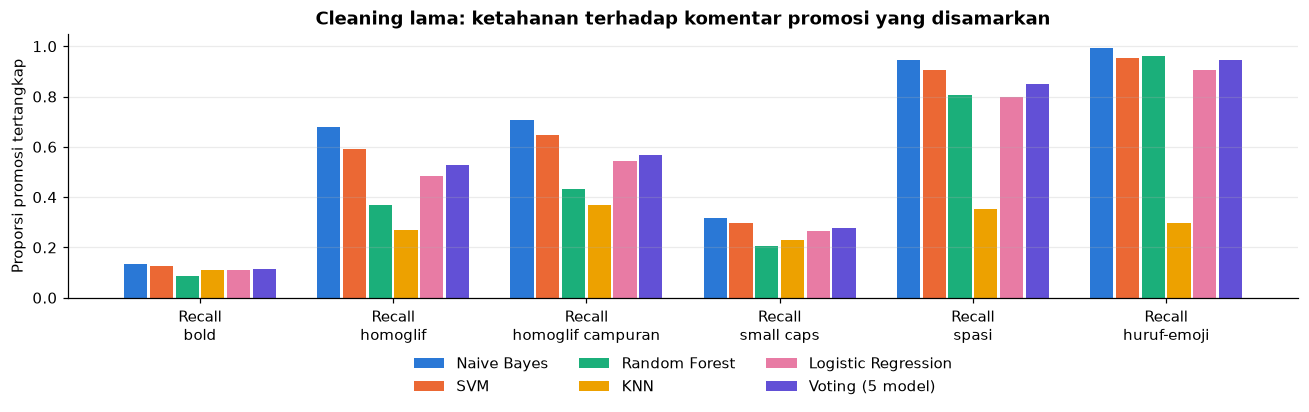

In [14]:
kol = [c for c in hasil_C.columns if c.startswith("Recall ")]
fig, ax = plt.subplots(figsize=(12, 4.2))
lebar = 0.8 / len(hasil_C)
for i, nama in enumerate(hasil_C.index):
    x = np.arange(len(kol)) + i * lebar - 0.4 + lebar / 2
    ax.bar(x, hasil_C.loc[nama, kol], width=lebar * 0.9, color=WARNA_MODEL[i], label=nama)
ax.set_xticks(np.arange(len(kol)), [k.replace("Recall ", "Recall\n") for k in kol])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Proporsi promosi tertangkap")
ax.set_title("Cleaning lama: ketahanan terhadap komentar promosi yang disamarkan")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.42), frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 6. Ringkasan

Hasil saat notebook ini diuji (angka bisa sedikit berbeda antar versi library):

**Bagian A - replikasi training lama:** angkanya identik dengan laporan lama (SVM F1 0.969 / akurasi 0.971, KNN akurasi 0.822).
Replikasi berhasil, tetapi angka ini optimis karena kebocoran data.

**Bagian B - cleaning training vs prediksi:** 439 dari 1.684 baris uji (26%) hasil cleaning-nya berbeda, tetapi dampaknya
ke F1 kecil (-0.016 s/d +0.006). Risiko terbesarnya bukan di sini, melainkan pada komentar yang disamarkan (Bagian C).

**Bagian C - protokol adil, cleaning lama vs cleaning v2 (notebook 02):**

| | Cleaning lama (`worker.py`) | Cleaning v2 + kolom sinyal |
|---|---|---|
| F1 voting 5 model | 0.927 | **0.974** |
| F1 SVM / RF / LR | 0.926 / 0.929 / 0.918 | **0.976 / 0.971 / 0.963** |
| False positive voting | 56 (dari ~1.200 komentar normal) | **10** (dari ~1.200 komentar normal) |
| Recall samaran huruf bold (voting) | **0.12** | 1.00 (LR) |
| Recall samaran homoglif Cyrillic | 0.53 | 0.99 (LR) |
| Recall samaran small caps | 0.28 | 1.00 (LR) |
| Recall samaran huruf dispasi | 0.85 | 1.00 (LR) |

(Data uji kedua notebook tidak identik karena hasil deduplikasi bergantung pada cleaning, tetapi protokolnya sama.)

Kesimpulan:
1. Laporan lama (F1 ~0.97) terlalu optimis. Dengan evaluasi yang adil, metode lama berada di F1 ~0.93.
2. Kelemahan utama cleaning lama adalah **non-ASCII**: huruf bold tidak dinormalisasi, sehingga 88% komentar promosi
   ber-huruf bold lolos. Spammer cukup mengganti gaya huruf untuk menghindari deteksi.
3. Emoji yang dihapus tanpa jejak juga membuang informasi (lihat token emoji di notebook 02/03).
4. Cleaning v2 menutup celah tersebut dan sekaligus menaikkan F1 pada data biasa.